11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Number of training images: 60000
Number of testing images: 10000
Training image shape: (60000, 28, 28)
Testing image shape: (10000, 28, 28)
Image dimensions: (28, 28)


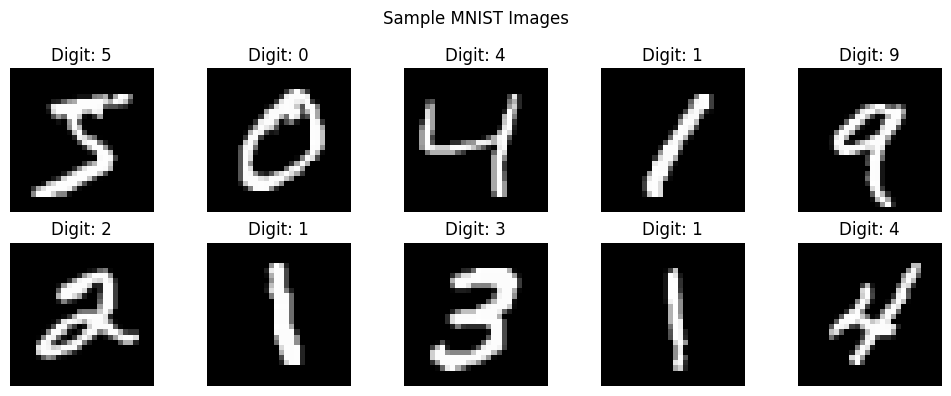

Preprocessed image shape: (60000, 28, 28, 1)
Minimum pixel value: -1.0
Maximum pixel value: 1.0
Part A completed successfully!


In [1]:
# EXPERIMENT 7 - PART A
# DATASET PREPARATION AND IMAGE PREPROCESSING

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import time

# Set random seeds
tf.random.set_seed(42)
np.random.seed(42)

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Explore the dataset
print("Number of training images:", len(x_train))
print("Number of testing images:", len(x_test))
print("Training image shape:", x_train.shape)
print("Testing image shape:", x_test.shape)
print("Image dimensions:", x_train.shape[1:])

# Display sample images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title("Digit: " + str(y_train[i]))
    plt.axis("off")

plt.suptitle("Sample MNIST Images")
plt.tight_layout()
plt.show()

# Normalize pixel values from [0, 255] to [-1, 1]
x_train = (x_train.astype("float32") - 127.5) / 127.5

# Reshape images to (28, 28, 1)
x_train = np.expand_dims(x_train, axis=-1)

print("Preprocessed image shape:", x_train.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

# Prepare dataset for batch-wise training
BATCH_SIZE = 128

train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(60000)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Part A completed successfully!")


GENERATOR MODEL SUMMARY


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 784,641 (2.99 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 12,672 (49.50 KB)

Generated image shape: (1, 28, 28, 1)


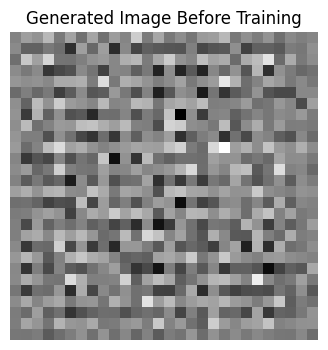

Part B completed successfully!


In [2]:
# EXPERIMENT 7 - PART B
# IMPLEMENTING THE GENERATOR

from tensorflow.keras import layers

# Dimension of the random noise vector
LATENT_DIM = 100

# Build Generator model
def build_generator():
    model = tf.keras.Sequential([
        layers.Input(shape=(LATENT_DIM,)),

        layers.Dense(7 * 7 * 128, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(negative_slope=0.2),

        layers.Reshape((7, 7, 128)),

        layers.Conv2DTranspose(
            64, kernel_size=4, strides=2,
            padding="same", use_bias=False
        ),
        layers.BatchNormalization(),
        layers.LeakyReLU(negative_slope=0.2),

        layers.Conv2DTranspose(
            1, kernel_size=4, strides=2,
            padding="same", activation="tanh"
        )
    ], name="Generator")

    return model


generator = build_generator()

# Display Generator architecture
print("GENERATOR MODEL SUMMARY")
generator.summary()

# Generate an image before training
noise = tf.random.normal([1, LATENT_DIM])
generated_image = generator(noise, training=False)

print("Generated image shape:", generated_image.shape)

# Display the generated image
plt.figure(figsize=(4, 4))
plt.imshow(
    generated_image[0, :, :, 0].numpy() * 0.5 + 0.5,
    cmap="gray"
)
plt.title("Generated Image Before Training")
plt.axis("off")
plt.show()

print("Part B completed successfully!")


In [3]:
# EXPERIMENT 7 - PART C
# IMPLEMENTING THE DISCRIMINATOR AND GAN MODEL

# Build Discriminator model
def build_discriminator():
    model = tf.keras.Sequential([
        layers.Input(shape=(28, 28, 1)),

        layers.Conv2D(
            64, kernel_size=4, strides=2, padding="same"
        ),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dropout(0.3),

        layers.Conv2D(
            128, kernel_size=4, strides=2, padding="same"
        ),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)
    ], name="Discriminator")

    return model


discriminator = build_discriminator()

# Compile Discriminator
discriminator.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001, beta_1=0.5
    ),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True)
)

print("DISCRIMINATOR MODEL SUMMARY")
discriminator.summary()

# Define GAN by combining Generator and Discriminator
# Freeze Discriminator while configuring the combined GAN
discriminator.trainable = False

gan_input = layers.Input(shape=(LATENT_DIM,))
generated_output = generator(gan_input)
gan_output = discriminator(generated_output)

gan = tf.keras.Model(
    gan_input, gan_output, name="GAN"
)

gan.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001, beta_1=0.5
    ),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True)
)

print("COMBINED GAN MODEL SUMMARY")
gan.summary()

# Restore Discriminator for the custom training loop in Part D
discriminator.trainable = True

print("Part C completed successfully!")


DISCRIMINATOR MODEL SUMMARY


Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Generator (Sequential)          │ (None, 28, 28, 1)      │       784,641 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       138,561 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 923,202 (3.52 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 151,233 (590.75 KB)

Part C completed successfully!


Epoch 1/30 | Generator Loss: 0.9906 | Discriminator Loss: 0.8880 | Time: 14.02 sec


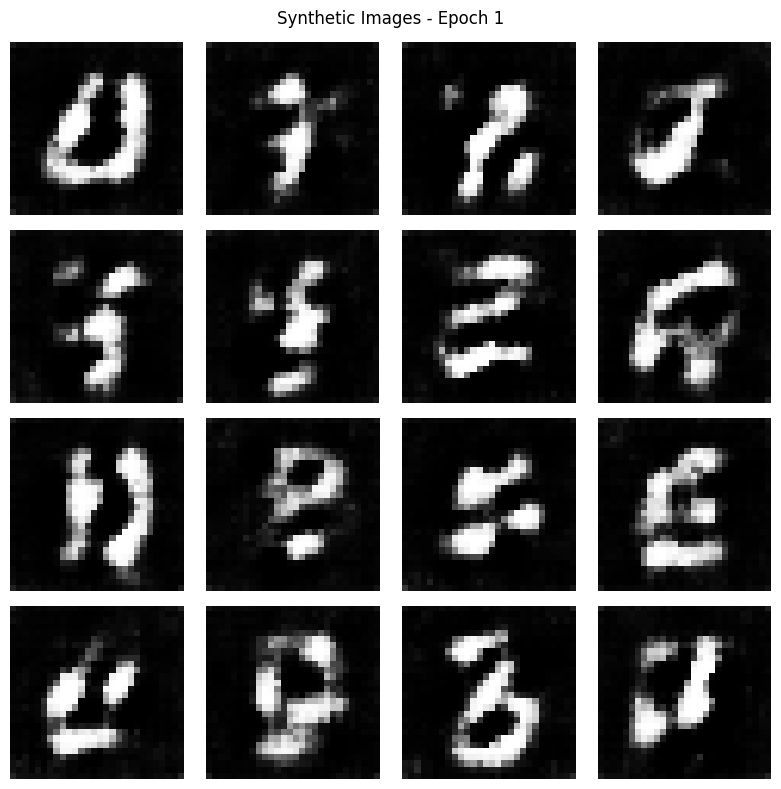

Epoch 2/30 | Generator Loss: 0.8760 | Discriminator Loss: 1.2092 | Time: 8.82 sec
Epoch 3/30 | Generator Loss: 0.8217 | Discriminator Loss: 1.2706 | Time: 7.68 sec
Epoch 4/30 | Generator Loss: 0.8587 | Discriminator Loss: 1.2222 | Time: 10.23 sec
Epoch 5/30 | Generator Loss: 0.9136 | Discriminator Loss: 1.1704 | Time: 7.77 sec


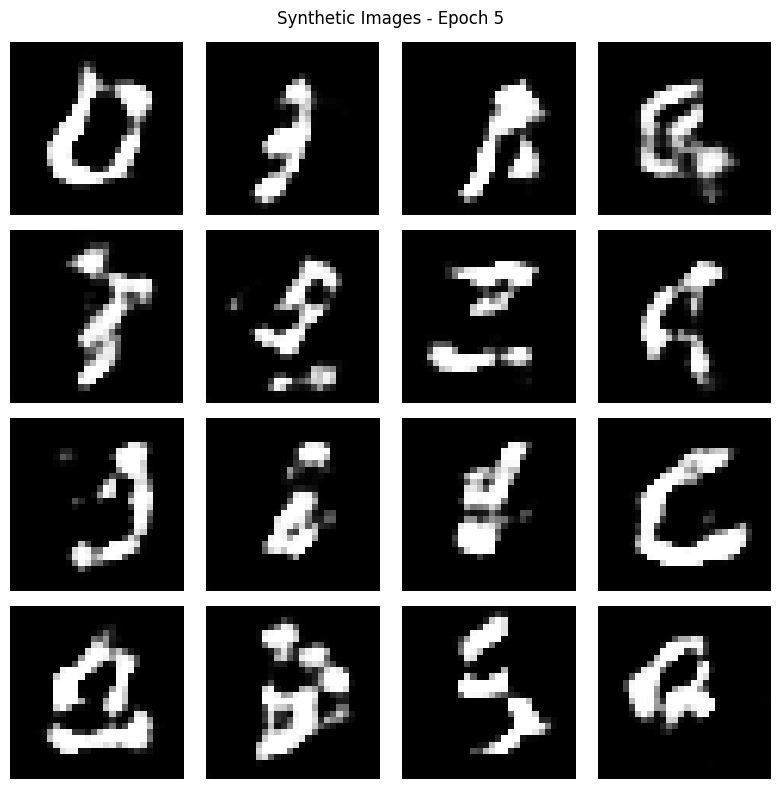

Epoch 6/30 | Generator Loss: 0.9391 | Discriminator Loss: 1.1497 | Time: 7.36 sec
Epoch 7/30 | Generator Loss: 0.9329 | Discriminator Loss: 1.1753 | Time: 8.21 sec
Epoch 8/30 | Generator Loss: 0.9188 | Discriminator Loss: 1.2022 | Time: 7.13 sec
Epoch 9/30 | Generator Loss: 0.9041 | Discriminator Loss: 1.2180 | Time: 7.30 sec
Epoch 10/30 | Generator Loss: 0.8911 | Discriminator Loss: 1.2260 | Time: 7.67 sec


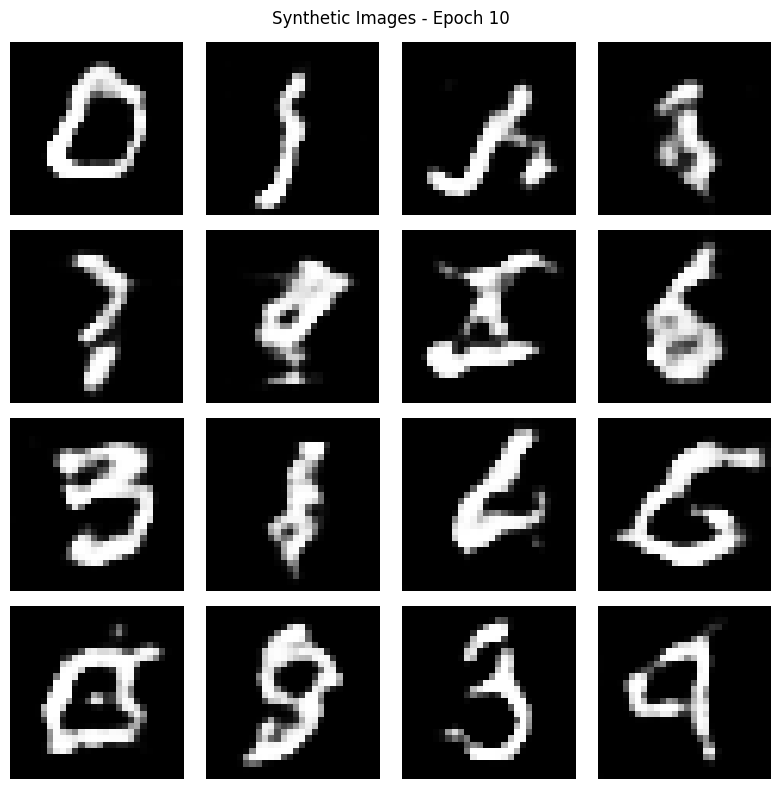

Epoch 11/30 | Generator Loss: 0.8785 | Discriminator Loss: 1.2413 | Time: 7.45 sec
Epoch 12/30 | Generator Loss: 0.8687 | Discriminator Loss: 1.2516 | Time: 7.55 sec
Epoch 13/30 | Generator Loss: 0.8555 | Discriminator Loss: 1.2669 | Time: 7.44 sec
Epoch 14/30 | Generator Loss: 0.8485 | Discriminator Loss: 1.2709 | Time: 7.37 sec
Epoch 15/30 | Generator Loss: 0.8435 | Discriminator Loss: 1.2736 | Time: 7.26 sec


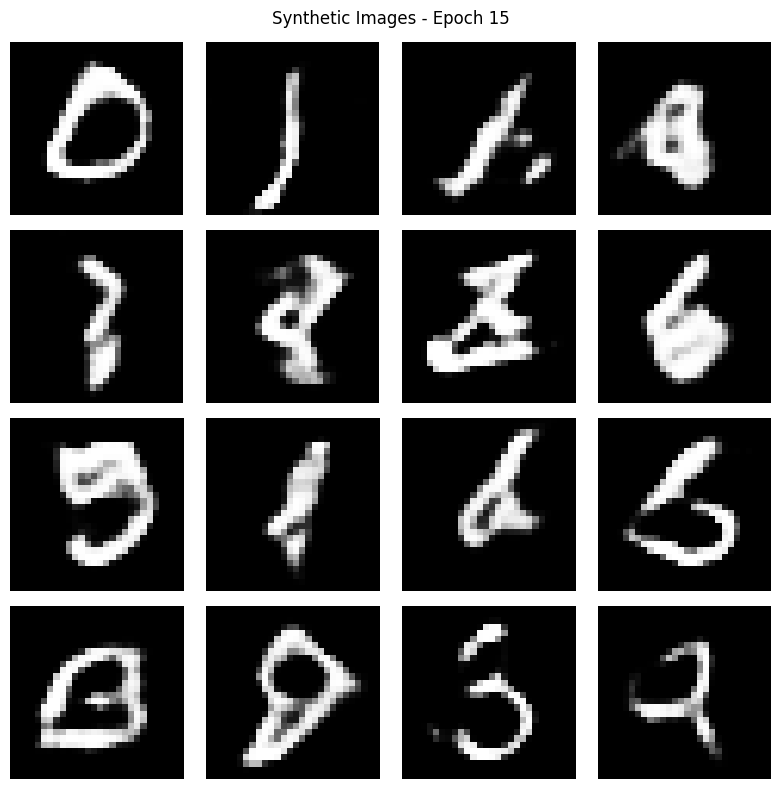

Epoch 16/30 | Generator Loss: 0.8441 | Discriminator Loss: 1.2693 | Time: 7.16 sec
Epoch 17/30 | Generator Loss: 0.8433 | Discriminator Loss: 1.2712 | Time: 7.20 sec
Epoch 18/30 | Generator Loss: 0.8469 | Discriminator Loss: 1.2648 | Time: 7.14 sec
Epoch 19/30 | Generator Loss: 0.8518 | Discriminator Loss: 1.2594 | Time: 7.20 sec
Epoch 20/30 | Generator Loss: 0.8563 | Discriminator Loss: 1.2549 | Time: 7.21 sec


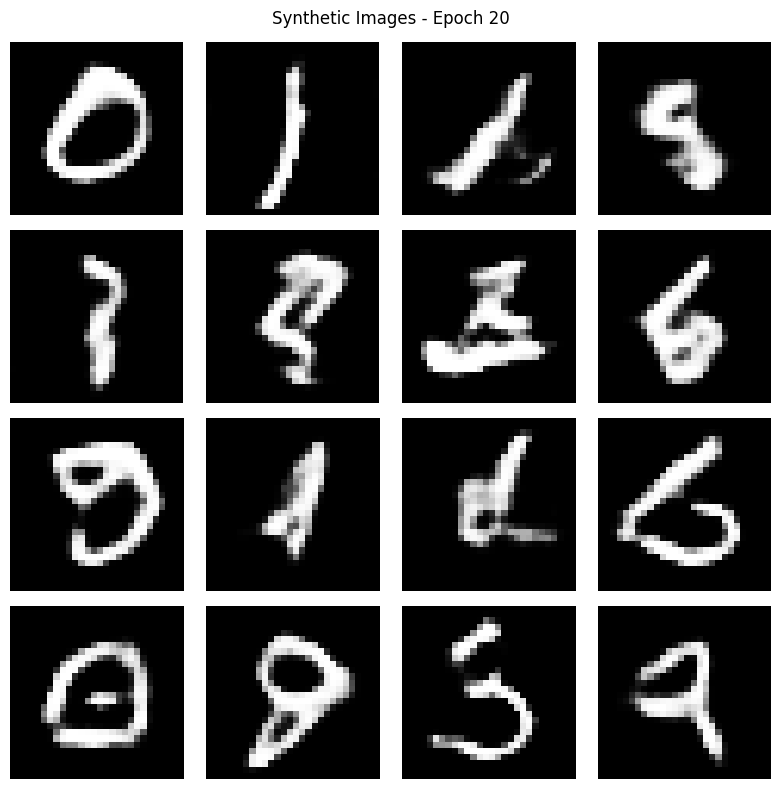

Epoch 21/30 | Generator Loss: 0.8605 | Discriminator Loss: 1.2522 | Time: 7.22 sec
Epoch 22/30 | Generator Loss: 0.8634 | Discriminator Loss: 1.2490 | Time: 7.29 sec
Epoch 23/30 | Generator Loss: 0.8698 | Discriminator Loss: 1.2457 | Time: 7.28 sec
Epoch 24/30 | Generator Loss: 0.8734 | Discriminator Loss: 1.2445 | Time: 7.61 sec
Epoch 25/30 | Generator Loss: 0.8751 | Discriminator Loss: 1.2429 | Time: 7.32 sec


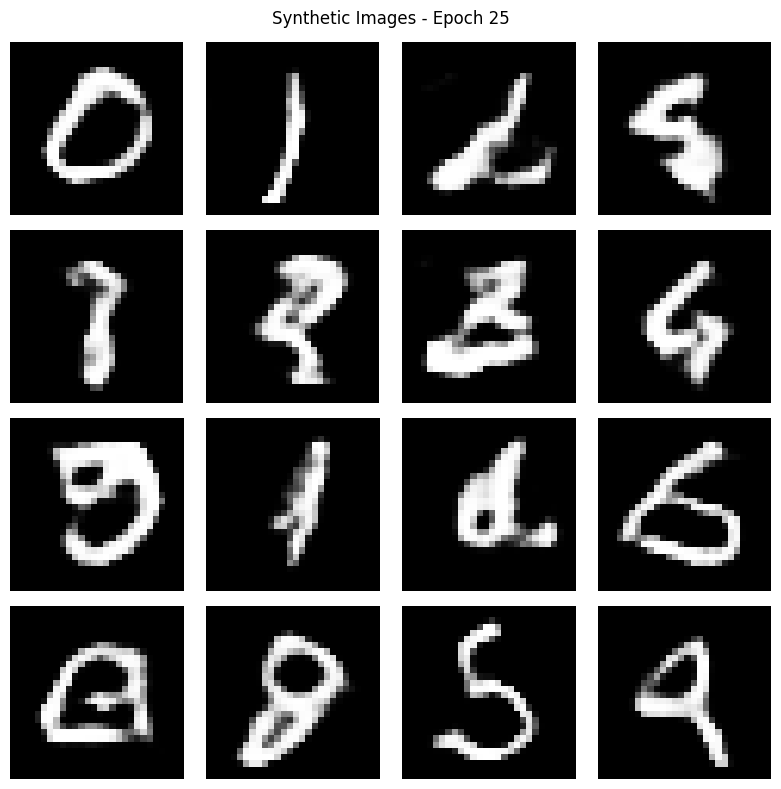

Epoch 26/30 | Generator Loss: 0.8833 | Discriminator Loss: 1.2366 | Time: 7.27 sec
Epoch 27/30 | Generator Loss: 0.8846 | Discriminator Loss: 1.2392 | Time: 7.30 sec
Epoch 28/30 | Generator Loss: 0.8866 | Discriminator Loss: 1.2350 | Time: 7.23 sec
Epoch 29/30 | Generator Loss: 0.8912 | Discriminator Loss: 1.2336 | Time: 7.26 sec
Epoch 30/30 | Generator Loss: 0.8903 | Discriminator Loss: 1.2364 | Time: 7.21 sec


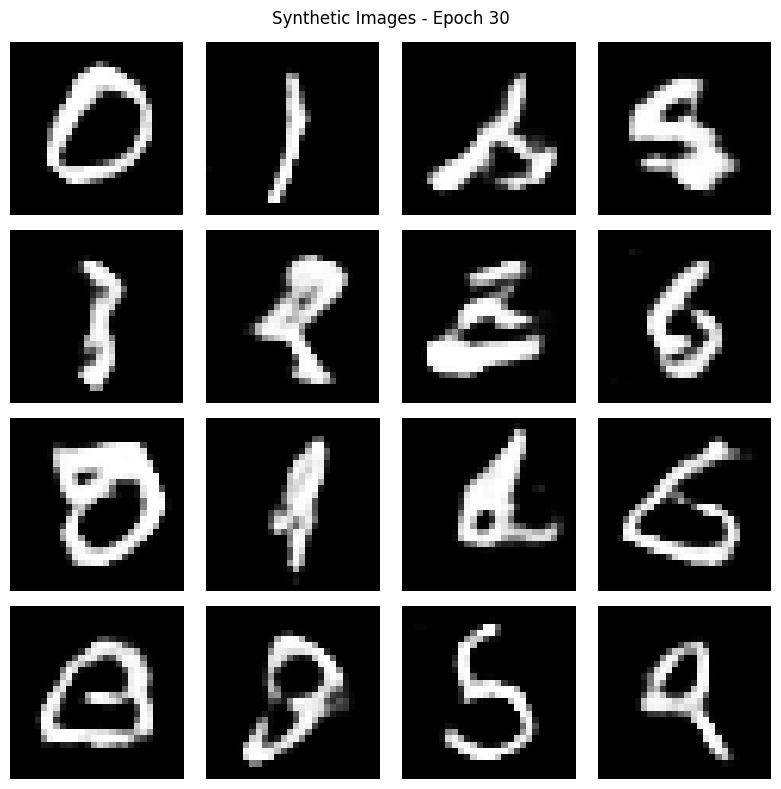

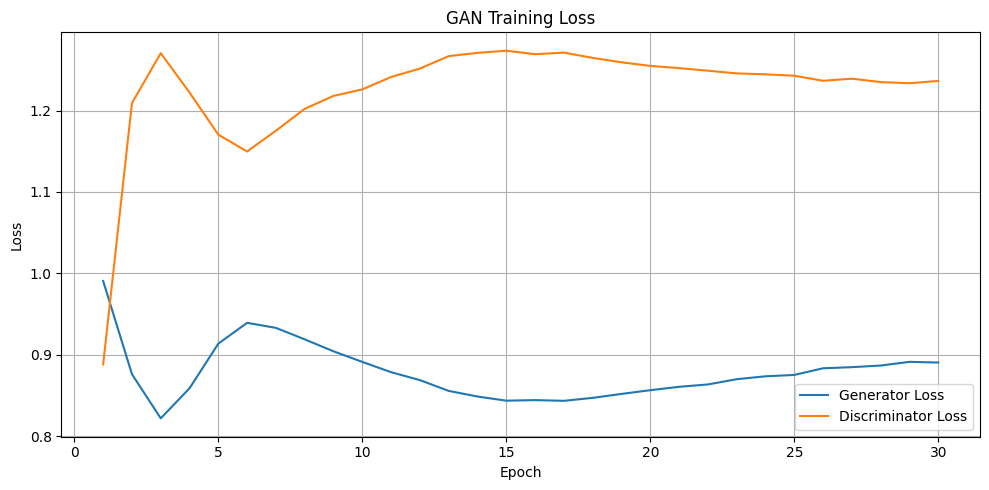

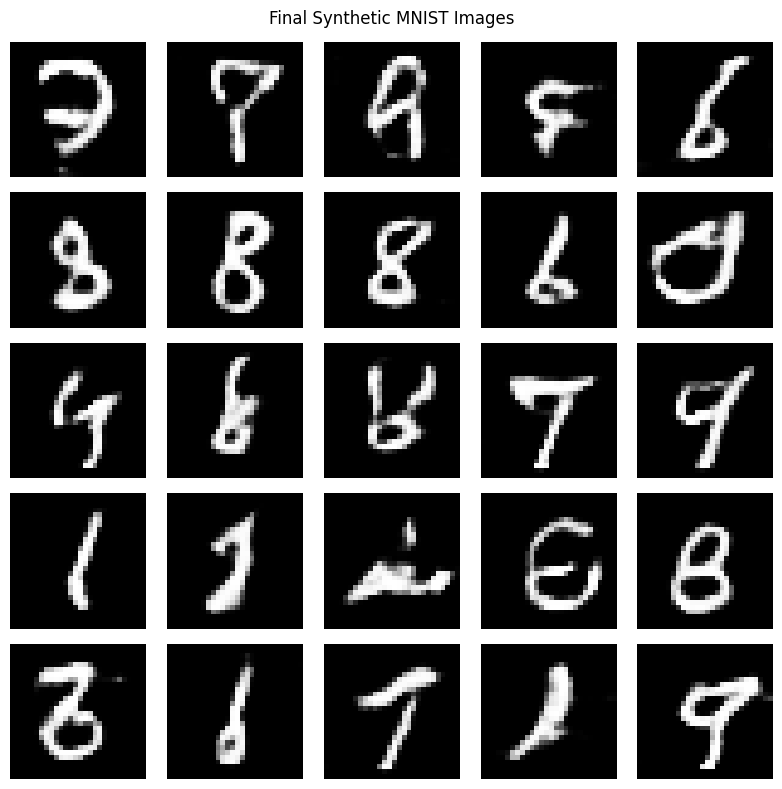

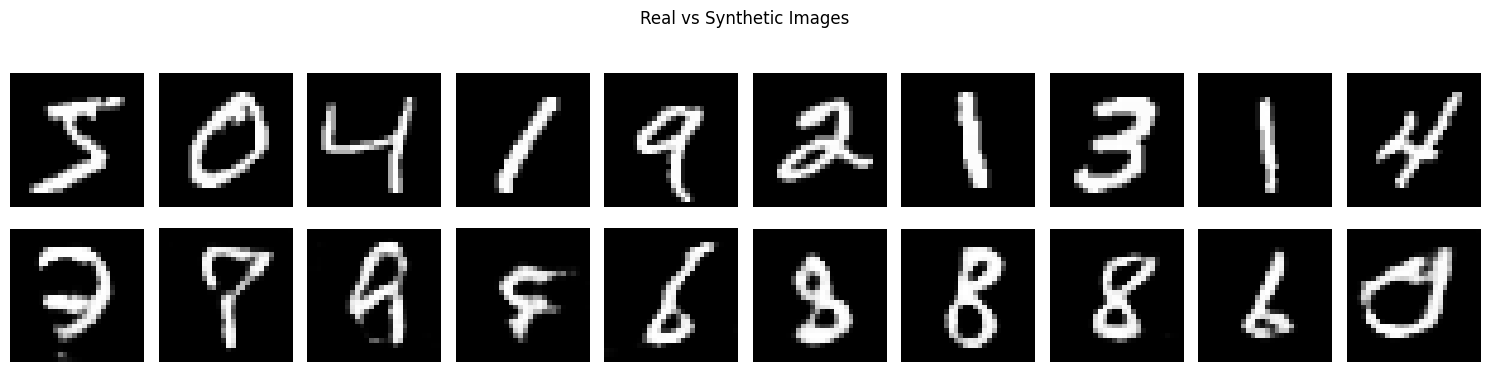

Part D completed successfully!
All results are saved in the gan_outputs folder.


In [4]:
# EXPERIMENT 7 - PART D
# GAN TRAINING AND SYNTHETIC IMAGE GENERATION

# Training configuration
EPOCHS = 30
NUM_EXAMPLES_TO_GENERATE = 16

# Create output folder
os.makedirs("gan_outputs", exist_ok=True)

# Fixed noise for comparing images across epochs
seed = tf.random.normal([NUM_EXAMPLES_TO_GENERATE, LATENT_DIM])

# Define loss functions
cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output), fake_output
    )

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(
        tf.ones_like(real_output), real_output
    )
    fake_loss = cross_entropy(
        tf.zeros_like(fake_output), fake_output
    )
    return real_loss + fake_loss


# Define optimizers
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0001, beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0001, beta_1=0.5
)

# Lists for recording losses
generator_losses = []
discriminator_losses = []


# Train the Generator and Discriminator for one batch
@tf.function
def train_step(real_images):

    noise = tf.random.normal([BATCH_SIZE, LATENT_DIM])

    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:

        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(
            real_output, fake_output
        )

    # Compute gradients
    gen_gradients = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )

    disc_gradients = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    # Update Generator
    generator_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )

    # Update Discriminator
    discriminator_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss


# Generate and save images after training intervals
def generate_and_save_images(model, epoch, test_input):

    predictions = model(test_input, training=False)

    fig = plt.figure(figsize=(8, 8))

    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i + 1)

        image = predictions[i, :, :, 0] * 0.5 + 0.5
        plt.imshow(image, cmap="gray")
        plt.axis("off")

    plt.suptitle("Synthetic Images - Epoch " + str(epoch))
    plt.tight_layout()

    plt.savefig(
        f"gan_outputs/epoch_{epoch:03d}.png"
    )
    plt.show()
    plt.close(fig)


# Training loop
for epoch in range(1, EPOCHS + 1):

    start_time = time.time()

    gen_metric = tf.keras.metrics.Mean()
    disc_metric = tf.keras.metrics.Mean()

    for image_batch in train_dataset:

        gen_loss, disc_loss = train_step(image_batch)

        gen_metric.update_state(gen_loss)
        disc_metric.update_state(disc_loss)

    g_loss = float(gen_metric.result())
    d_loss = float(disc_metric.result())

    generator_losses.append(g_loss)
    discriminator_losses.append(d_loss)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Generator Loss: {g_loss:.4f} | "
        f"Discriminator Loss: {d_loss:.4f} | "
        f"Time: {time.time() - start_time:.2f} sec"
    )

    # Generate images at regular intervals
    if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
        generate_and_save_images(generator, epoch, seed)


# Plot Generator and Discriminator losses
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS + 1),
    generator_losses,
    label="Generator Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    discriminator_losses,
    label="Discriminator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("gan_outputs/training_losses.png")
plt.show()


# Generate final synthetic images
final_noise = tf.random.normal([25, LATENT_DIM])
final_images = generator(final_noise, training=False)

plt.figure(figsize=(8, 8))

for i in range(25):
    plt.subplot(5, 5, i + 1)

    image = final_images[i, :, :, 0] * 0.5 + 0.5
    plt.imshow(image, cmap="gray")
    plt.axis("off")

plt.suptitle("Final Synthetic MNIST Images")
plt.tight_layout()

plt.savefig("gan_outputs/final_synthetic_images.png")
plt.show()


# Compare real and synthetic images
fig, axes = plt.subplots(2, 10, figsize=(15, 4))

for i in range(10):
    axes[0, i].imshow(x_train[i].squeeze(), cmap="gray")
    axes[0, i].axis("off")

    synthetic_image = final_images[i, :, :, 0] * 0.5 + 0.5
    axes[1, i].imshow(synthetic_image, cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Real", fontsize=10)
axes[1, 0].set_ylabel("Synthetic", fontsize=10)

plt.suptitle("Real vs Synthetic Images")
plt.tight_layout()

plt.savefig("gan_outputs/real_vs_synthetic.png")
plt.show()

# Save the trained Generator
generator.save("gan_outputs/trained_generator.keras")

print("Part D completed successfully!")
print("All results are saved in the gan_outputs folder.")
